# Tutorial 03c

This notebook grows decision trees on the same trips, then combines them by bagging, a random forest, and boosting. The label is the mode: `car`, `walk`, `transit`, or `bike`.

The last cell puts these models next to the logistic regression from tutorial 03a, the linear SVM from tutorial 03b, and one XGBoost model. The table gives precision, recall, and AUC for each mode. Macro F1 is the average of the four mode F1 scores. Macro AUC is the average of the four mode AUCs. Accuracy mostly follows the car class.


## Open this notebook

- **Colab.** Replace `github.com` with `githubtocolab.com` in the repository URL, then open this file. Run the setup cell so Colab can see `mode_choice.csv`.
- **On your own computer.** Open this file from the `03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)` folder, so `mode_choice.csv` sits beside the notebook.


In [1]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    os.chdir(repo / LESSON_DIR)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/03 Classification Models (Logistics regression and Decision Trees and Ensemble Learning)


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds the table, Matplotlib draws the figures, scikit-learn fits the models, and XGBoost fits the extra boosting model in the last table.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
xgboost 3.4.1
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After it finishes, restart the kernel and run the cells above again.


In [3]:
%pip install numpy pandas matplotlib scikit-learn xgboost


Note: you may need to restart the kernel to use updated packages.


## The trips

`mode_choice.csv` is the same VISTA 2024–2025 file as in the earlier tutorials. The rows were shuffled once. Take the first 75% as the training set and the last 25% as the test set.

Trees split one column at a time, so the numeric columns stay in their original units. The comparison at the end uses these same columns for every model, including the linear SVM.


In [4]:
trips = pd.read_csv("mode_choice.csv")
n_train = int(len(trips) * 0.75)
train = trips.iloc[:n_train].copy()
test = trips.iloc[n_train:].copy()
print("train", len(train), "rows")
print("test ", len(test), "rows")

num = ["distance_km", "travel_min", "start_hour", "hh_vehicles", "hh_bikes"]
cat = ["purpose", "day_type", "age_group", "sex", "car_licence", "employed"]
train_ready = pd.concat([
    train[num],
    pd.get_dummies(train[cat], dtype=int),
], axis=1)
test_ready = pd.concat([
    test[num],
    pd.get_dummies(test[cat], dtype=int),
], axis=1)
test_ready = test_ready.reindex(columns=train_ready.columns, fill_value=0)
print("columns", train_ready.shape[1])


train 13260 rows
test  4420 rows
columns 44


## One tree

Each split picks the column and the cut that reduce the Gini index the most. The lecture stops a tree in two ways: a maximum depth, or a minimum number of trips in a leaf. With no limit, the tree can keep splitting until every training leaf is pure, and the training score reaches 1. Check whether the test score is still moving.

Each panel is one mode, scored against the other three, using that mode's predicted probability. Several depths share a panel. The macro AUC in the table is the average of the four mode AUCs.


max_depth  train macro F1  test macro F1  test macro AUC  test accuracy
        1           0.392          0.387           0.646          0.825
        2           0.393          0.388           0.763          0.845
        3           0.447          0.445           0.824          0.891
        4           0.454          0.451           0.850          0.900
        6           0.623          0.601           0.886          0.918
        8           0.731          0.680           0.901          0.924
       12           0.896          0.694           0.877          0.920
       16           0.974          0.718           0.848          0.917
     none           1.000          0.728           0.840          0.918


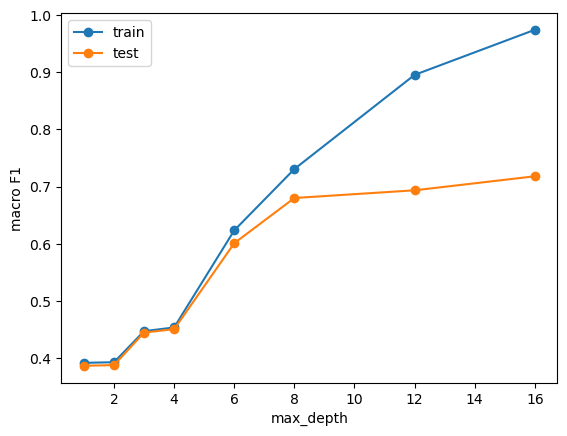

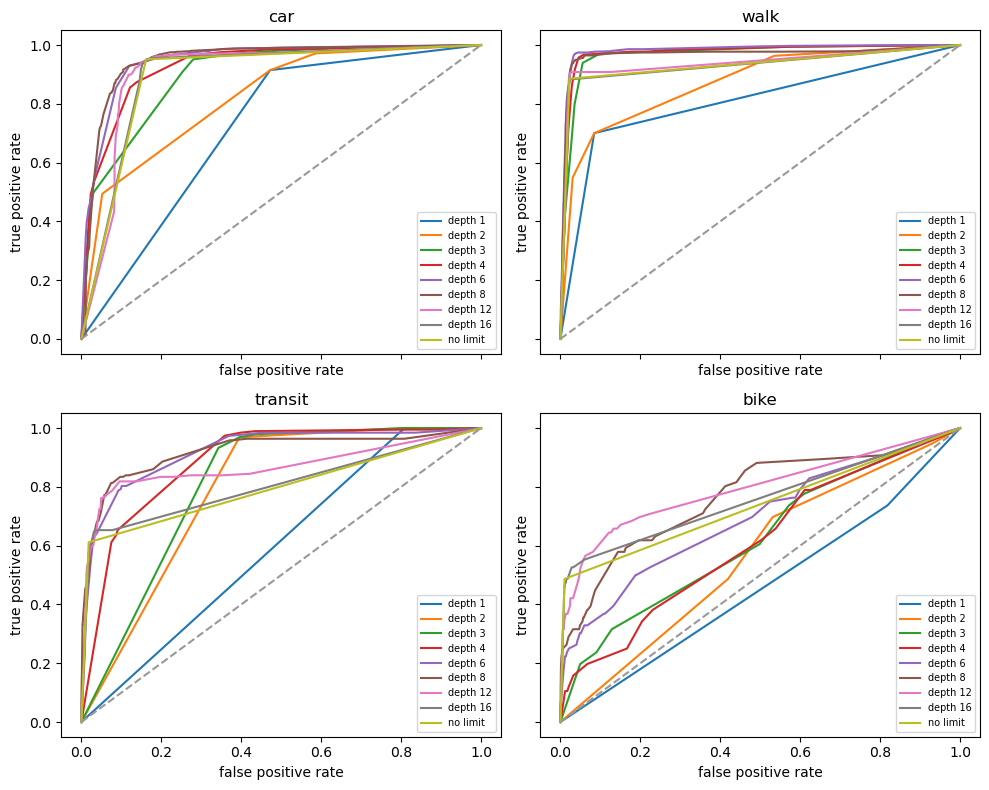

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, roc_curve

depth_rows = []
roc_scores = []
for depth in [1, 2, 3, 4, 6, 8, 12, 16, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=0)
    model.fit(train_ready, train["mode"])
    train_pred = model.predict(train_ready)
    test_pred = model.predict(test_ready)
    proba = model.predict_proba(test_ready)
    auc = roc_auc_score(test["mode"], proba, multi_class="ovr", average="macro", labels=model.classes_)
    depth_rows.append({
        "max_depth": "none" if depth is None else depth,
        "train macro F1": f1_score(train["mode"], train_pred, average="macro"),
        "test macro F1": f1_score(test["mode"], test_pred, average="macro"),
        "test macro AUC": auc,
        "test accuracy": accuracy_score(test["mode"], test_pred),
    })
    roc_scores.append(("no limit" if depth is None else f"depth {depth}", proba, list(model.classes_)))

depth_table = pd.DataFrame(depth_rows)
print(depth_table.round(3).to_string(index=False))

plt.plot(depth_table.loc[depth_table["max_depth"] != "none", "max_depth"].astype(int), depth_table.loc[depth_table["max_depth"] != "none", "train macro F1"], marker="o", label="train")
plt.plot(depth_table.loc[depth_table["max_depth"] != "none", "max_depth"].astype(int), depth_table.loc[depth_table["max_depth"] != "none", "test macro F1"], marker="o", label="test")
plt.xlabel("max_depth")
plt.ylabel("macro F1")
plt.legend()
plt.show()

mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in roc_scores:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# Past depth 8 the test macro F1 still rises a little, to about 0.728 with no depth limit.
# Test macro AUC moves the other way: about 0.901 at depth 8, and about 0.840 with no limit.
# A pure leaf stores a probability of 0 or 1, so the ranking that macro AUC reads gets worse.


## The first three levels

The drawing stops at depth 3 so the splits can be read. The color is the mode the tree would predict if it stopped in that box. A deeper tree keeps cutting these boxes.


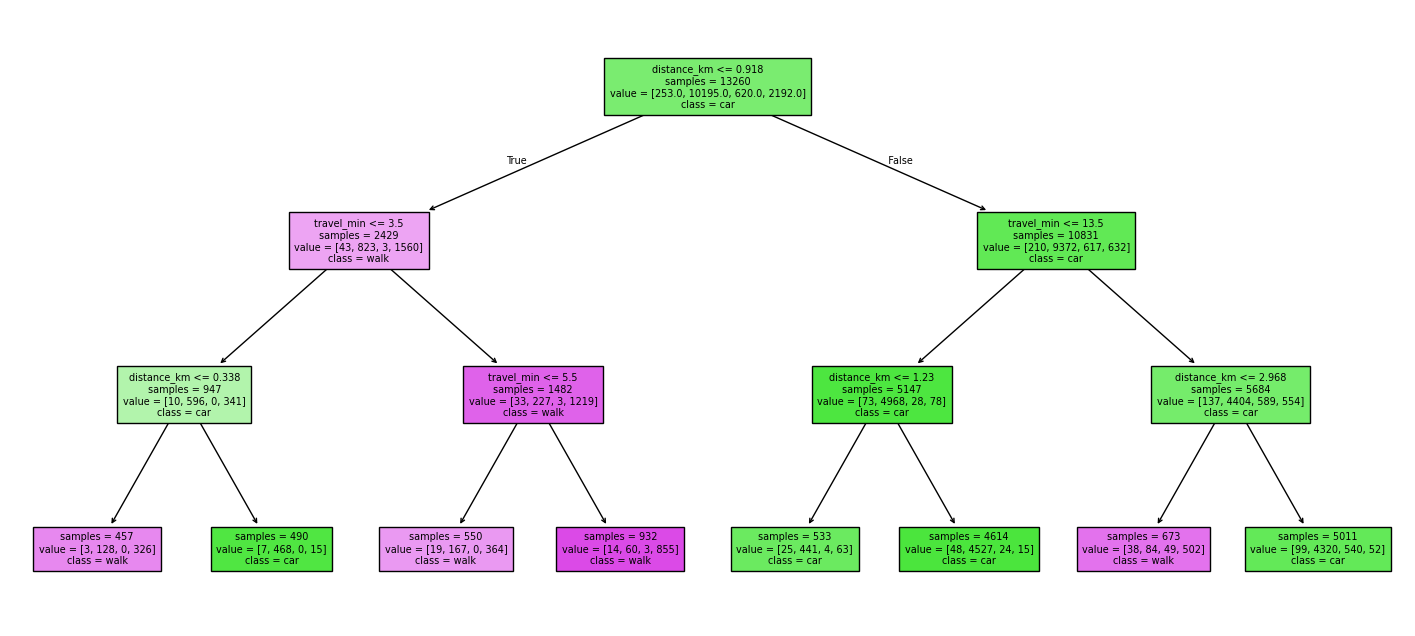

In [6]:
from sklearn.tree import plot_tree

small = DecisionTreeClassifier(max_depth=3, random_state=0)
small.fit(train_ready, train["mode"])
plt.figure(figsize=(18, 8))
plot_tree(
    small,
    feature_names=list(train_ready.columns),
    class_names=list(small.classes_),
    filled=True,
    fontsize=7,
    impurity=False,
)
plt.show()


## Minimum leaf size

`min_samples_leaf` is the other stop from the lecture. A larger leaf refuses splits that would leave only a few trips on one side. The cell grows a tree with no depth limit, at two leaf sizes. Each mode has its own panel, with both leaf sizes on it.


 min_samples_leaf  train macro F1  test macro F1  test macro AUC
                1           1.000          0.728           0.840
               50           0.593          0.593           0.929


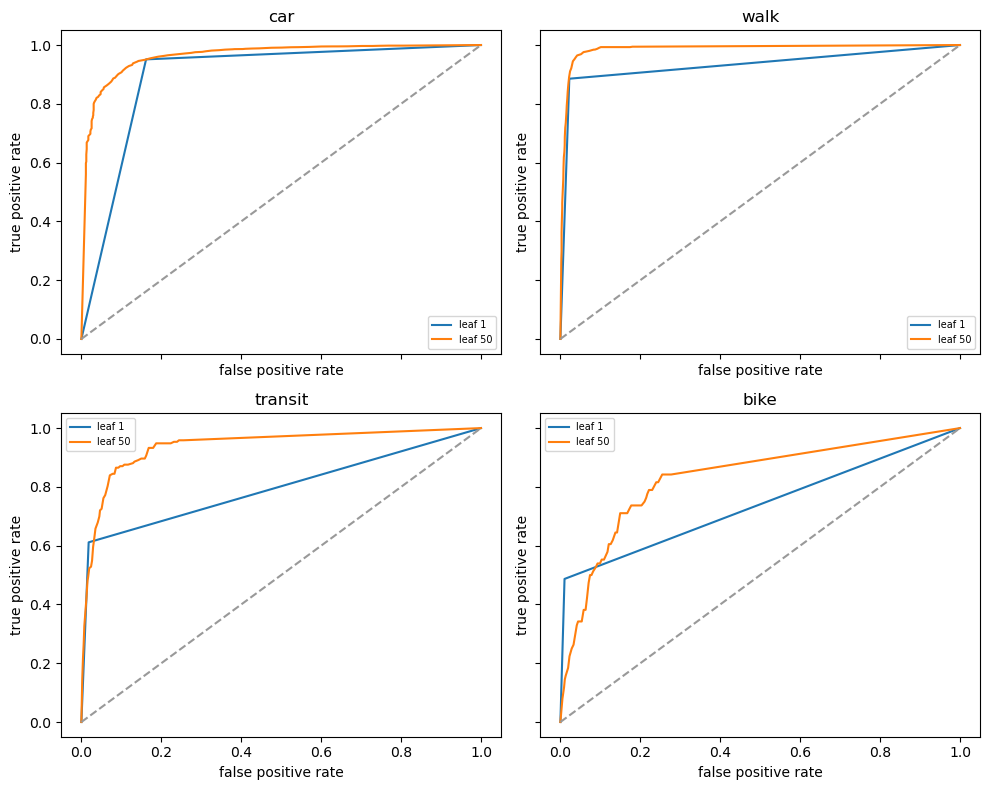

In [7]:
leaf_rows = []
roc_curves = []
for leaf in [1, 50]:
    model = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=0)
    model.fit(train_ready, train["mode"])
    proba = model.predict_proba(test_ready)
    auc = roc_auc_score(test["mode"], proba, multi_class="ovr", average="macro", labels=model.classes_)
    leaf_rows.append({
        "min_samples_leaf": leaf,
        "train macro F1": f1_score(train["mode"], model.predict(train_ready), average="macro"),
        "test macro F1": f1_score(test["mode"], model.predict(test_ready), average="macro"),
        "test macro AUC": auc,
    })
    roc_curves.append((f"leaf {leaf}", proba, list(model.classes_)))
print(pd.DataFrame(leaf_rows).round(3).to_string(index=False))
mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in roc_curves:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# A minimum leaf of 50 has a lower test macro F1, about 0.593, and a higher test macro AUC, about 0.929.
# The unlimited tree's test macro F1 is about 0.728 and its test macro AUC is about 0.840.


## Bagging and a random forest

Bagging draws bootstrap samples of the training rows, fits one tree on each sample, and lets the trees vote. A random forest adds one restriction: each split may look at only `m` of the columns. In scikit-learn that subset is `max_features`. `"sqrt"` is a subset. Setting it to every column, `None`, is bagging.

The first loop grows a forest and changes only the number of trees. The second cell keeps 100 trees and changes the column subset.


 trees  test accuracy  test macro F1  test macro AUC
    20          0.935          0.734           0.960
    50          0.939          0.744           0.973
   100          0.941          0.746           0.975
   200          0.942          0.749           0.976


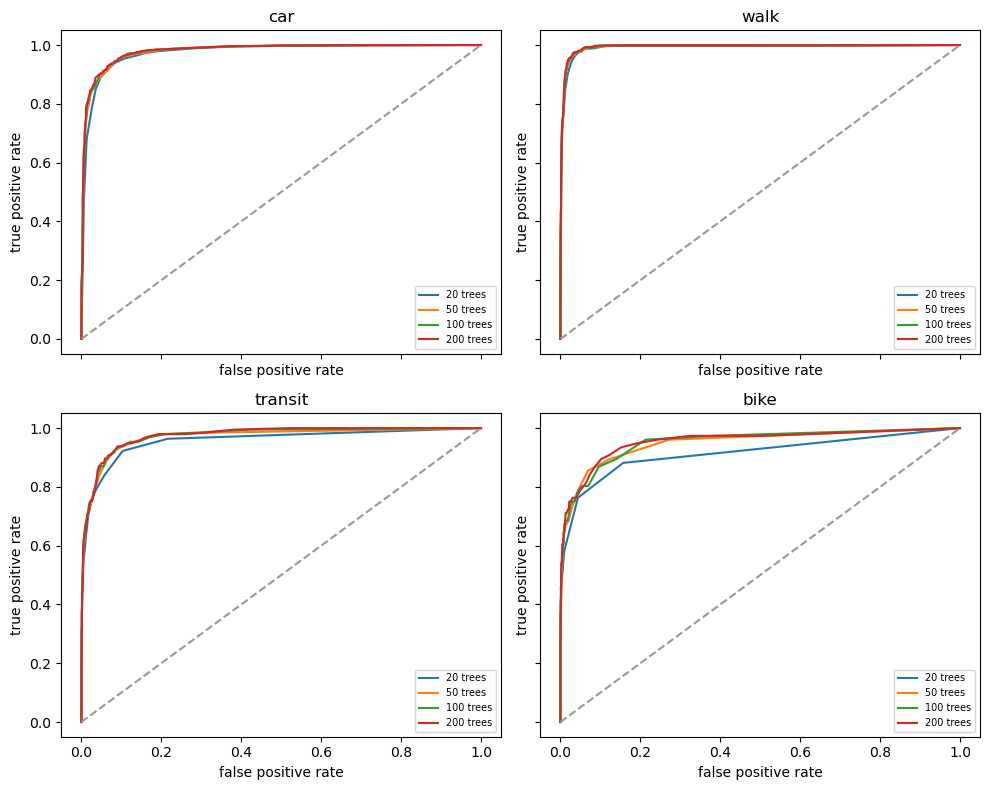

In [8]:
from sklearn.ensemble import RandomForestClassifier

forest_rows = []
roc_curves = []
for n_trees in [20, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n_trees, random_state=0)
    model.fit(train_ready, train["mode"])
    pred = model.predict(test_ready)
    proba = model.predict_proba(test_ready)
    auc = roc_auc_score(test["mode"], proba, multi_class="ovr", average="macro", labels=model.classes_)
    forest_rows.append({
        "trees": n_trees,
        "test accuracy": accuracy_score(test["mode"], pred),
        "test macro F1": f1_score(test["mode"], pred, average="macro"),
        "test macro AUC": auc,
    })
    roc_curves.append((f"{n_trees} trees", proba, list(model.classes_)))
forest_table = pd.DataFrame(forest_rows)
print(forest_table.round(3).to_string(index=False))
mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in roc_curves:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


    split columns  test accuracy  test macro F1  test macro AUC
subset of columns          0.941          0.746           0.975
      all columns          0.948          0.796           0.965


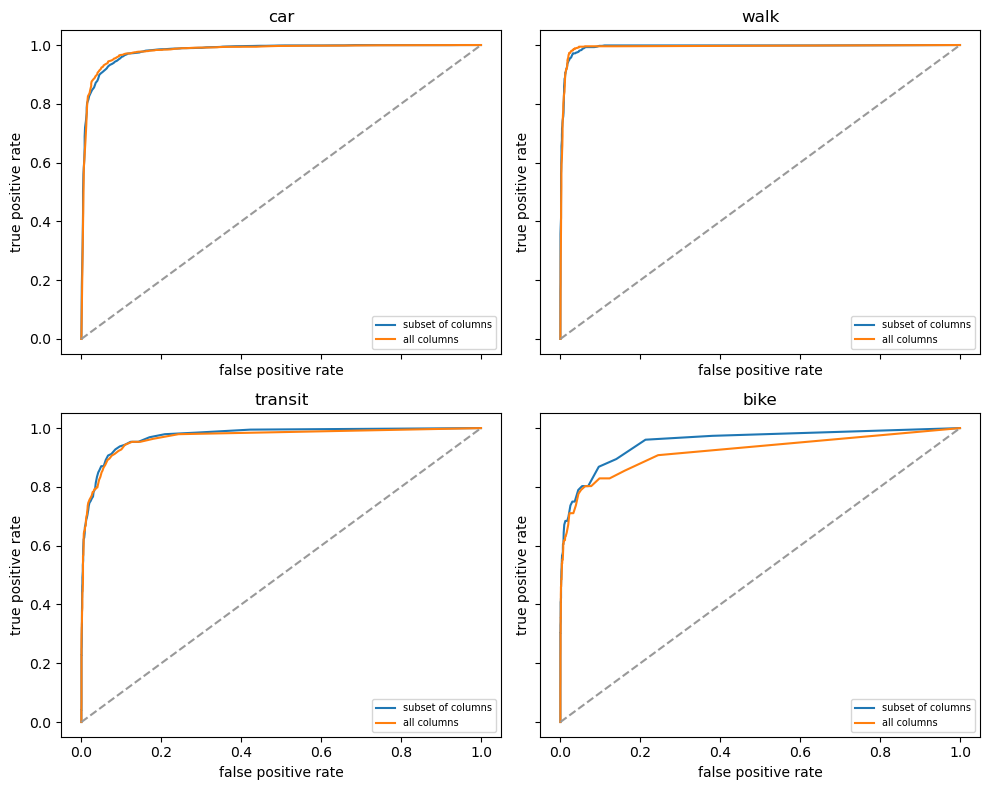

In [9]:
subset_rows = []
roc_curves = []
for name, max_features in [("subset of columns", "sqrt"), ("all columns", None)]:
    model = RandomForestClassifier(n_estimators=100, max_features=max_features, random_state=0)
    model.fit(train_ready, train["mode"])
    pred = model.predict(test_ready)
    proba = model.predict_proba(test_ready)
    auc = roc_auc_score(test["mode"], proba, multi_class="ovr", average="macro", labels=model.classes_)
    subset_rows.append({
        "split columns": name,
        "test accuracy": accuracy_score(test["mode"], pred),
        "test macro F1": f1_score(test["mode"], pred, average="macro"),
        "test macro AUC": auc,
    })
    roc_curves.append((name, proba, list(model.classes_)))
print(pd.DataFrame(subset_rows).round(3).to_string(index=False))
mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in roc_curves:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# All columns is bagging. A subset of columns is a random forest.
# Keep the row with the higher test macro F1. On this table the two need not follow the usual textbook order.

# All columns has the higher test macro F1, about 0.796 against 0.746.
# A subset of columns has the higher test macro AUC, about 0.975 against 0.965.


## Boosting

Boosting fits the next tree to what the current trees still get wrong. These trees are not a bootstrap sample. `learning_rate` shrinks each tree's vote. A small rate usually needs more trees before the test score catches up.

The loop keeps the rate at 0.1 and changes the number of trees. Each tree is limited to depth 3, which is scikit-learn's default for this model. Each mode has its own panel, with those three fits on it.

XGBoost is another way to do boosting. It also adds trees one after another, and it penalizes a tree that grows too large, so one tree does not dominate the sum. The comparison table fits one XGBoost model with the same number of trees, learning rate, and depth as the gradient boosting row of 100 trees.


 trees  learning_rate  test accuracy  test macro F1  test macro AUC
    50            0.1          0.930          0.655           0.965
   100            0.1          0.933          0.691           0.973
   200            0.1          0.937          0.719           0.978


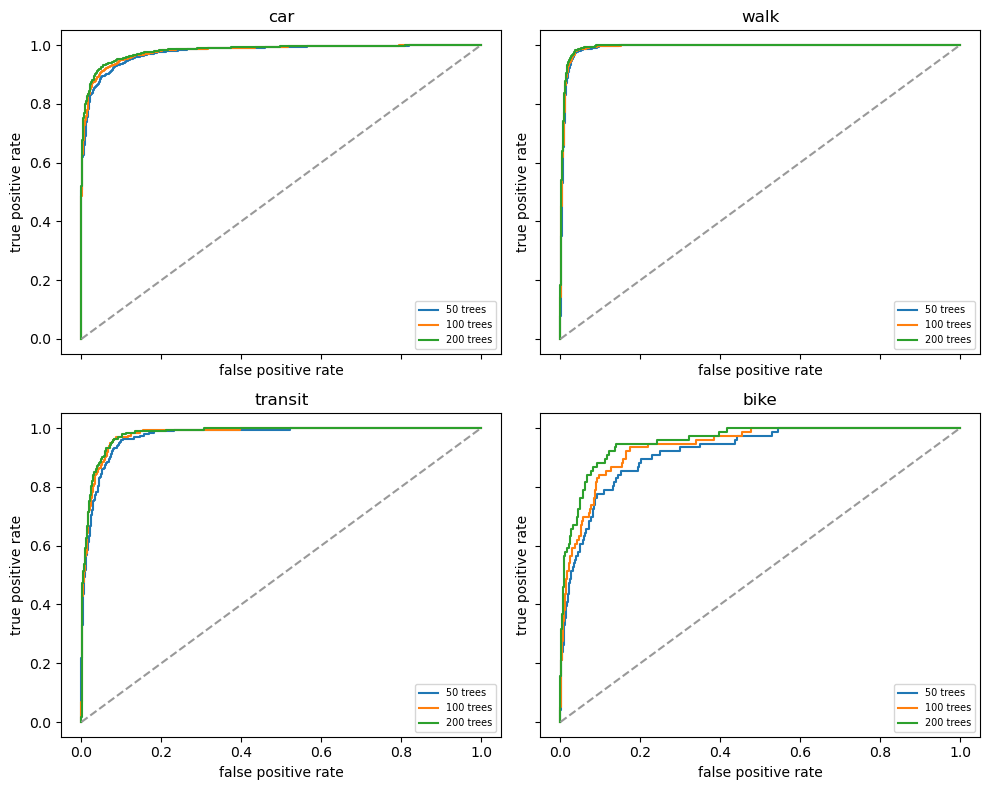

In [10]:
from sklearn.ensemble import GradientBoostingClassifier

boost_rows = []
roc_curves = []
for n_trees in [50, 100, 200]:
    model = GradientBoostingClassifier(
        n_estimators=n_trees, learning_rate=0.1, max_depth=3, random_state=0,
    )
    model.fit(train_ready, train["mode"])
    pred = model.predict(test_ready)
    proba = model.predict_proba(test_ready)
    auc = roc_auc_score(test["mode"], proba, multi_class="ovr", average="macro", labels=model.classes_)
    boost_rows.append({
        "trees": n_trees,
        "learning_rate": 0.1,
        "test accuracy": accuracy_score(test["mode"], pred),
        "test macro F1": f1_score(test["mode"], pred, average="macro"),
        "test macro AUC": auc,
    })
    roc_curves.append((f"{n_trees} trees", proba, list(model.classes_)))
boost_table = pd.DataFrame(boost_rows)
print(boost_table.round(3).to_string(index=False))
mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in roc_curves:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


## One table for the models so far

Each row is one setting, not a finished search. Every model uses the original columns. XGBoost needs integer class labels, so the mode names are numbered for that one fit and turned back into names afterwards.

The table has precision, recall, and AUC for each mode. Macro F1 is the average of the four F1 scores, one score per mode. Macro AUC is the average of the four AUCs printed in the same row. Each ROC panel is one mode, and the curves on it are the models. Accuracy stays high because most trips are by car.


                                          model  car precision  car recall  car AUC  walk precision  walk recall  walk AUC  transit precision  transit recall  transit AUC  bike precision  bike recall  bike AUC  macro F1  macro AUC
                bagging, 100 trees, all columns          0.963       0.978    0.981           0.907        0.953     0.993              0.835           0.601        0.968           0.850        0.447     0.919     0.796      0.965
         random forest, 100 trees, sqrt columns          0.946       0.985    0.981           0.926        0.917     0.994              0.858           0.503        0.974           1.000        0.303     0.953     0.746      0.975
gradient boosting, 100 trees, learning rate 0.1          0.952       0.973    0.979           0.884        0.938     0.992              0.735           0.503        0.980           0.737        0.184     0.939     0.691      0.973
                            tree, max_depth = 8          0.947       0.967  

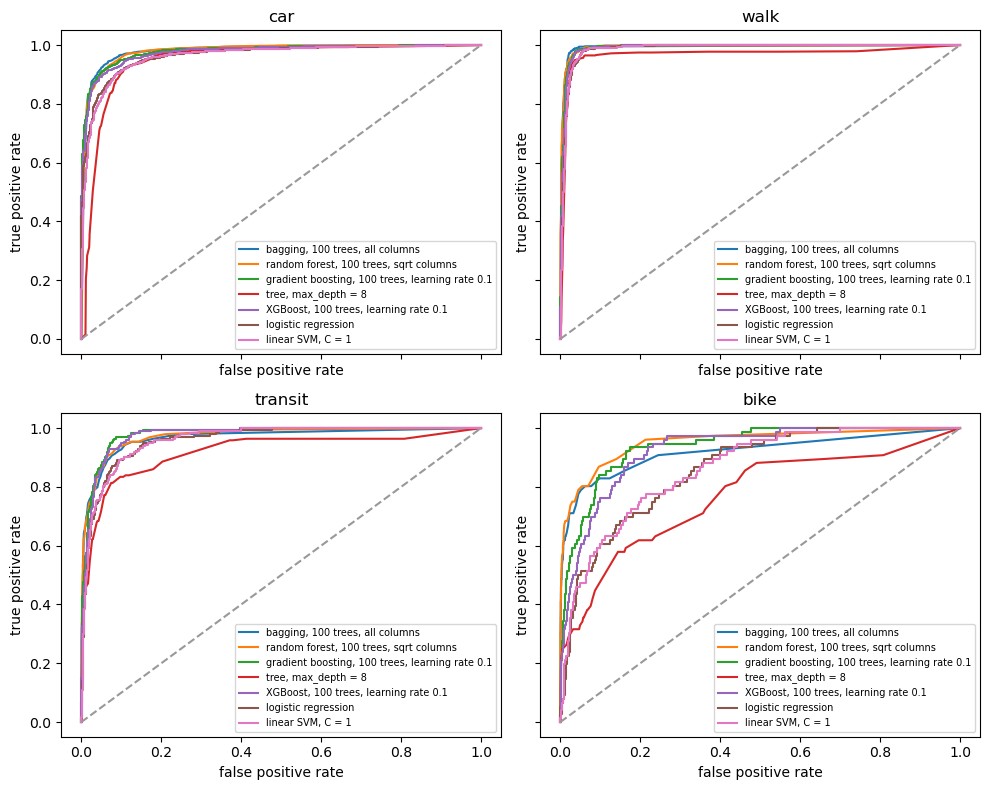

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

logistic = LogisticRegression(max_iter=2000)
logistic.fit(train_ready, train["mode"])
linear_svm = SVC(kernel="linear", C=1, probability=True)
linear_svm.fit(train_ready, train["mode"])
one_tree = DecisionTreeClassifier(max_depth=8, random_state=0)
one_tree.fit(train_ready, train["mode"])
bagging = RandomForestClassifier(n_estimators=100, max_features=None, random_state=0)
bagging.fit(train_ready, train["mode"])
forest = RandomForestClassifier(n_estimators=100, max_features="sqrt", random_state=0)
forest.fit(train_ready, train["mode"])
boosting = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=0,
)
boosting.fit(train_ready, train["mode"])
encoder = LabelEncoder()
train_code = encoder.fit_transform(train["mode"])
xgb_model = XGBClassifier(
    n_estimators=100, learning_rate=0.1, max_depth=3, random_state=0, verbosity=0,
)
xgb_model.fit(train_ready, train_code)

names = [
    "logistic regression",
    "linear SVM, C = 1",
    "tree, max_depth = 8",
    "bagging, 100 trees, all columns",
    "random forest, 100 trees, sqrt columns",
    "gradient boosting, 100 trees, learning rate 0.1",
    "XGBoost, 100 trees, learning rate 0.1",
]
sklearn_models = [logistic, linear_svm, one_tree, bagging, forest, boosting]

from sklearn.metrics import precision_score, recall_score

order = ["car", "walk", "transit", "bike"]
rows = []
drawn = []
for name, model in zip(names, sklearn_models):
    pred = model.predict(test_ready)
    proba = model.predict_proba(test_ready)
    class_names = list(model.classes_)
    precision = precision_score(
        test["mode"], pred, average=None, labels=class_names, zero_division=0,
    )
    recall = recall_score(
        test["mode"], pred, average=None, labels=class_names, zero_division=0,
    )
    aucs = roc_auc_score(
        test["mode"], proba, multi_class="ovr", average=None, labels=class_names,
    )
    row = {"model": name}
    for mode_name in order:
        k = class_names.index(mode_name)
        row[f"{mode_name} precision"] = precision[k]
        row[f"{mode_name} recall"] = recall[k]
        row[f"{mode_name} AUC"] = aucs[k]
    row["macro F1"] = f1_score(test["mode"], pred, average="macro")
    row["macro AUC"] = roc_auc_score(
        test["mode"], proba, multi_class="ovr", average="macro", labels=class_names,
    )
    rows.append(row)
    drawn.append((name, proba, class_names))

xgb_pred = encoder.inverse_transform(xgb_model.predict(test_ready))
xgb_proba = xgb_model.predict_proba(test_ready)
xgb_names = list(encoder.classes_)
precision = precision_score(
    test["mode"], xgb_pred, average=None, labels=xgb_names, zero_division=0,
)
recall = recall_score(
    test["mode"], xgb_pred, average=None, labels=xgb_names, zero_division=0,
)
aucs = roc_auc_score(
    test["mode"], xgb_proba, multi_class="ovr", average=None, labels=xgb_names,
)
row = {"model": names[-1]}
for mode_name in order:
    k = xgb_names.index(mode_name)
    row[f"{mode_name} precision"] = precision[k]
    row[f"{mode_name} recall"] = recall[k]
    row[f"{mode_name} AUC"] = aucs[k]
row["macro F1"] = f1_score(test["mode"], xgb_pred, average="macro")
row["macro AUC"] = roc_auc_score(
    test["mode"], xgb_proba, multi_class="ovr", average="macro", labels=xgb_names,
)
rows.append(row)
drawn.append((names[-1], xgb_proba, xgb_names))

columns = ["model"]
for mode_name in order:
    columns += [f"{mode_name} precision", f"{mode_name} recall", f"{mode_name} AUC"]
columns += ["macro F1", "macro AUC"]
compare = pd.DataFrame(rows)[columns].sort_values("macro F1", ascending=False)
print(compare.round(3).to_string(index=False))

by_name = {name: (proba, class_names) for name, proba, class_names in drawn}
ordered = [(name, *by_name[name]) for name in compare["model"]]
mode_order = ["car", "walk", "transit", "bike"]
fig, axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
for ax, mode_name in zip(axes.ravel(), mode_order):
    for label, proba, class_names in ordered:
        k = list(class_names).index(mode_name)
        fpr, tpr, _ = roc_curve(test["mode"] == mode_name, proba[:, k])
        ax.plot(fpr, tpr, label=label)
    ax.plot([0, 1], [0, 1], color="0.6", linestyle="--")
    ax.set_title(mode_name)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

# This list uses one setting of each model. Another depth, another C, or more trees can reorder it.
# Macro F1 is the average of the four mode F1 scores. Macro AUC is the average of the four mode AUCs.
# Sorted by macro F1, bagging leads this list at about 0.796.
# The random forest has macro AUC about 0.975, gradient boosting about 0.973, and bagging about 0.965.
# XGBoost, with the same 100 trees and learning rate 0.1, has macro F1 about 0.637 and macro AUC about 0.967.
